# Projeto NP2 — Redes Neurais

## Classificação de Imagens de Vestuário com PyTorch

O objetivo deste projeto é desenvolver uma rede neural artificial capaz de identificar diferentes categorias de roupas e acessórios utilizando o dataset **FashionMNIST**.

O FashionMNIST contém **70.000 imagens**, em escala de cinza, com resolução de **28 × 28 pixels**, distribuídas em **10 categorias**.

Será utilizada uma rede neural profunda desenvolvida em PyTorch, com etapas de preparação dos dados, treinamento, validação e avaliação. Ao final, serão analisados o desempenho do modelo, a capacidade de generalização e as curvas de aprendizado.


In [12]:
# 1. IMPORTAÇÃO DAS BIBLIOTECAS

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score, mean_squared_error

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Utilizando dispositivo: {device}')

Utilizando dispositivo: cpu


### Entendendo o Dataset customizado

A classe `MeuDataset` transforma as entradas em tensores `float32` e os rótulos em tensores `long`, adequados à classificação multiclasse com `CrossEntropyLoss`. Os métodos `__len__` e `__getitem__` permitem que o `DataLoader` acesse as amostras em lotes.

In [13]:
# 2. ESTRUTURAÇÃO DO DATASET (Customizado)

class MeuDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

### Definição do problema e preparação dos dados

O FashionMNIST é um problema de **classificação multiclasse**, com 10 possibilidades de saída. As imagens, originalmente com dimensão `28 × 28`, são convertidas para vetores de **784 valores** porque adotaremos uma rede do tipo **MLP**. Os valores dos pixels, originalmente entre 0 e 255, são normalizados para o intervalo de 0 a 1.

Usaremos 48.000 imagens para treinamento, 12.000 para validação e 10.000 imagens oficiais reservadas para teste. A divisão entre treino e validação preserva a proporção das classes. Os dados de teste não serão usados para ajustar o modelo.

In [14]:
# 3. PREPARAÇÃO DOS DADOS E DATALOADER

fashion_train = datasets.FashionMNIST(root='dados', train=True, download=True)
fashion_test = datasets.FashionMNIST(root='dados', train=False, download=True)

X = fashion_train.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
y = fashion_train.targets.numpy()

X_test = fashion_test.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
y_test = fashion_test.targets.numpy()

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

train_dataset = MeuDataset(X_train, y_train)
val_dataset = MeuDataset(X_val, y_val)
test_dataset = MeuDataset(X_test, y_test)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print('Treinamento:', len(train_dataset), 'imagens')
print('Validação:', len(val_dataset), 'imagens')
print('Teste:', len(test_dataset), 'imagens')

imagens, rotulos = next(iter(train_loader))
print('Formato do lote de imagens:', imagens.shape)
print('Formato do lote de rótulos:', rotulos.shape)

Treinamento: 48000 imagens
Validação: 12000 imagens
Teste: 10000 imagens
Formato do lote de imagens: torch.Size([32, 784])
Formato do lote de rótulos: torch.Size([32])


### Conferência das dimensões dos dados

Com `batch_size = 32`, cada lote de entrada possui **32 imagens**, representadas por tensores `float32` com formato `[32, 784]`. Os respectivos rótulos são tensores `int64` (`torch.long`) com formato `[32]` e valores de 0 a 9.

Após passar pela rede neural, cada lote produz um tensor de saída de formato `[32, 10]`, contendo 10 valores (*logits*) para cada imagem. A classe prevista é obtida pelo índice do maior valor (`argmax`).

O conjunto foi dividido em **48.000 imagens para treino**, **12.000 para validação** e **10.000 para teste**. A separação de teste é mantida independente do ajuste do modelo.

### Arquitetura da Rede Neural

Foi desenvolvida uma rede neural do tipo Multi-Layer Perceptron (MLP), utilizando PyTorch. A arquitetura possui uma camada de entrada com 784 características, três camadas ocultas com 256, 128 e 64 neurônios e uma camada de saída com 10 neurônios.

Foram utilizadas as funções de ativação ReLU, normalização Batch Normalization e regularização Dropout de 30%, com o objetivo de melhorar o aprendizado e reduzir o risco de overfitting.

In [15]:

# 4. ARQUITETURA DA REDE NEURAL

class MinhaRedeNeural(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.camada1 = nn.Linear(input_dim, 256)
        self.norm1 = nn.BatchNorm1d(256)

        self.camada2 = nn.Linear(256, 128)
        self.norm2 = nn.BatchNorm1d(128)

        self.camada3 = nn.Linear(128, 64)
        self.camada_saida = nn.Linear(64, output_dim)

        self.ativacao = nn.ReLU()
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = self.camada1(x)
        x = self.norm1(x)
        x = self.ativacao(x)
        x = self.dropout(x)

        x = self.camada2(x)
        x = self.norm2(x)
        x = self.ativacao(x)
        x = self.dropout(x)

        x = self.camada3(x)
        x = self.ativacao(x)

        x = self.camada_saida(x)
        return x


input_size = 784
output_size = 10

model = MinhaRedeNeural(input_size, output_size).to(device)

print(model)

total_parametros = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Parâmetros treináveis:', total_parametros)


MinhaRedeNeural(
  (camada1): Linear(in_features=784, out_features=256, bias=True)
  (norm1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (camada2): Linear(in_features=256, out_features=128, bias=True)
  (norm2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (camada3): Linear(in_features=128, out_features=64, bias=True)
  (camada_saida): Linear(in_features=64, out_features=10, bias=True)
  (ativacao): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
)
Parâmetros treináveis: 243530


### Topologia e parâmetros treináveis

A rede foi implementada por meio da classe `MinhaRedeNeural`, herdando de `torch.nn.Module`. A entrada é um vetor com 784 características e a saída contém 10 *logits*, um por classe.

| Camada | Dimensão de entrada → saída | Técnica / ativação | Parâmetros treináveis |
|---|---|---|---:|
| Linear 1 | 784 → 256 | ReLU após normalização | 200.960 |
| BatchNorm 1 | 256 → 256 | Normalização de ativações | 512 |
| Dropout 1 | 256 → 256 | Taxa de 30% | 0 |
| Linear 2 | 256 → 128 | ReLU após normalização | 32.896 |
| BatchNorm 2 | 128 → 128 | Normalização de ativações | 256 |
| Dropout 2 | 128 → 128 | Taxa de 30% | 0 |
| Linear 3 | 128 → 64 | ReLU | 8.256 |
| Camada de saída | 64 → 10 | Sem ativação final (*logits*) | 650 |
| **Total** | | | **243.530** |

Os parâmetros foram contabilizados a partir dos pesos e vieses das camadas lineares e dos parâmetros treináveis das camadas de Batch Normalization. ReLU e Dropout não possuem parâmetros treináveis. A saída não usa Softmax porque a função `CrossEntropyLoss` trabalha diretamente com *logits*.

### Hiperparâmetros de Treinamento

Para o treinamento da rede neural, foi utilizada a função de perda CrossEntropyLoss, adequada para problemas de classificação multiclasse.

O otimizador escolhido foi o Adam, com taxa de aprendizado de 0.001, por oferecer atualizações adaptativas dos pesos. Também foi aplicada regularização L2 por meio do Weight Decay de 0.0001, visando reduzir o risco de overfitting.

O tamanho do mini-batch foi definido como 32, permitindo o processamento dos dados em pequenos lotes durante o treinamento.

In [16]:
# 5. HIPERPARÂMETROS, PERDA E OTIMIZADOR

criterion = nn.CrossEntropyLoss()

learning_rate = 0.001
weight_decay = 1e-4

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

print('Função de perda:', criterion)
print('Taxa de aprendizado:', learning_rate)
print('Weight Decay:', weight_decay)
print('Otimizador: Adam')


Função de perda: CrossEntropyLoss()
Taxa de aprendizado: 0.001
Weight Decay: 0.0001
Otimizador: Adam


### Treinamento e Validação da Rede Neural

O treinamento foi implementado manualmente utilizando PyTorch, com um limite de 50 épocas. Durante cada época, a rede realiza previsões, calcula a função de perda e atualiza seus pesos por meio da retropropagação dos gradientes.

Após o treinamento de cada época, o modelo é avaliado utilizando os dados de validação, sem realizar atualizações nos pesos.

Também foi implementado o Early Stopping, com paciência de cinco épocas, para interromper o treinamento quando a perda de validação deixar de melhorar. Os melhores pesos são armazenados e restaurados ao final do processo.

Durante a execução, são registrados os valores de perda e acurácia de treinamento e validação para posterior análise da convergência.

In [17]:

# 6. CICLO DE TREINAMENTO E VALIDAÇÃO

import copy

num_epochs = 50
patience = 5
patience_counter = 0
best_val_loss = float('inf')

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_weights = copy.deepcopy(model.state_dict())
best_epoch = 0

for epoch in range(num_epochs):

    # TREINAMENTO
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == targets).sum().item()
        total += targets.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # VALIDAÇÃO
    model.eval()
    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_val_loss += loss.item() * inputs.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == targets).sum().item()
            val_total += targets.size(0)

    val_loss = running_val_loss / val_total
    val_acc = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f'Época {epoch + 1}/{num_epochs} | '
          f'Loss Treino: {train_loss:.4f} | '
          f'Loss Validação: {val_loss:.4f} | '
          f'Acurácia: {val_acc:.2%}')

    # EARLY STOPPING
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print('Early Stopping ativado!')
        break

model.load_state_dict(best_weights)

print('Treinamento finalizado!')
print('Melhor época:', best_epoch)
print('Menor Loss de validação:', round(best_val_loss, 4))


Época 1/50 | Loss Treino: 0.5781 | Loss Validação: 0.3834 | Acurácia: 85.93%
Época 2/50 | Loss Treino: 0.4503 | Loss Validação: 0.3575 | Acurácia: 87.09%
Época 3/50 | Loss Treino: 0.4166 | Loss Validação: 0.3350 | Acurácia: 87.63%
Época 4/50 | Loss Treino: 0.3935 | Loss Validação: 0.3497 | Acurácia: 86.87%
Época 5/50 | Loss Treino: 0.3826 | Loss Validação: 0.3201 | Acurácia: 88.50%
Época 6/50 | Loss Treino: 0.3664 | Loss Validação: 0.3131 | Acurácia: 88.52%
Época 7/50 | Loss Treino: 0.3609 | Loss Validação: 0.3224 | Acurácia: 88.15%
Época 8/50 | Loss Treino: 0.3483 | Loss Validação: 0.3268 | Acurácia: 87.78%
Época 9/50 | Loss Treino: 0.3454 | Loss Validação: 0.3054 | Acurácia: 88.95%
Época 10/50 | Loss Treino: 0.3442 | Loss Validação: 0.3074 | Acurácia: 88.53%
Época 11/50 | Loss Treino: 0.3343 | Loss Validação: 0.3024 | Acurácia: 88.90%
Época 12/50 | Loss Treino: 0.3327 | Loss Validação: 0.2966 | Acurácia: 89.12%
Época 13/50 | Loss Treino: 0.3294 | Loss Validação: 0.3012 | Acurácia: 89

### Análise das Curvas de Aprendizado

Para acompanhar o desempenho da rede neural, foram gerados gráficos de perda (Loss) e acurácia durante as épocas de treinamento.

Os gráficos permitem comparar os resultados dos conjuntos de treinamento e validação, identificando a evolução do aprendizado e possíveis sinais de overfitting ou underfitting.

Também foi utilizado o Early Stopping, responsável por interromper o treinamento após cinco épocas consecutivas sem redução da perda de validação, mantendo os melhores pesos encontrados.

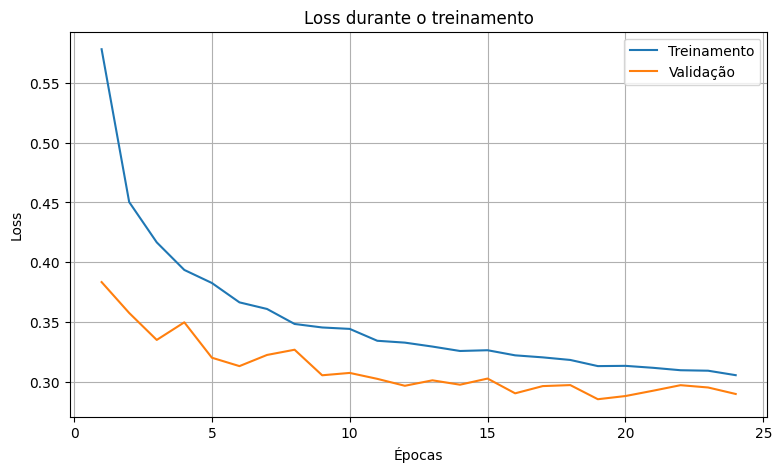

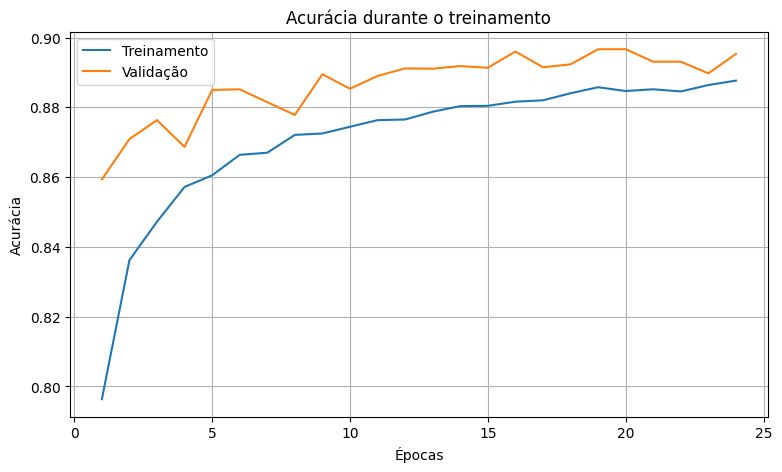

Épocas executadas: 24
Melhor época: 19
Menor Loss de validação: 0.2854
Acurácia na melhor época: 89.67%


In [18]:

# 7. ANÁLISE E PLOTAGEM DE RESULTADOS

epocas = range(1, len(train_losses) + 1)

# GRÁFICO DE LOSS
plt.figure(figsize=(9, 5))

plt.plot(epocas, train_losses, label='Treinamento')
plt.plot(epocas, val_losses, label='Validação')

plt.title('Loss durante o treinamento')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# GRÁFICO DE ACURÁCIA
plt.figure(figsize=(9, 5))

plt.plot(epocas, train_accuracies, label='Treinamento')
plt.plot(epocas, val_accuracies, label='Validação')

plt.title('Acurácia durante o treinamento')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)
plt.show()

# RESUMO DOS RESULTADOS
print('Épocas executadas:', len(train_losses))
print('Melhor época:', best_epoch)
print('Menor Loss de validação:', round(best_val_loss, 4))
print('Acurácia na melhor época:', f'{val_accuracies[best_epoch - 1]:.2%}')


### Análise dos Resultados do Treinamento

Durante o treinamento, a rede neural apresentou uma redução gradual da Loss e um aumento da acurácia, demonstrando que o modelo conseguiu aprender padrões presentes nas imagens.

O treinamento foi realizado durante 24 épocas, sendo interrompido pelo Early Stopping. A melhor época foi a 19ª, com Loss de validação de 0.2854 e acurácia de 89,67%.

Os gráficos mostram uma convergência satisfatória, com pequenas oscilações na validação e sem sinais expressivos de overfitting. A utilização de Dropout, Weight Decay e Early Stopping contribuiu para controlar o treinamento.

De modo geral, os resultados de validação foram positivos. A capacidade de generalização do modelo será avaliada posteriormente utilizando o conjunto de teste.

### Avaliação em Dados de Teste

Após o treinamento e a recuperação dos melhores pesos salvos pelo Early Stopping, o modelo é avaliado em **10.000 imagens de teste não utilizadas no treinamento nem na seleção dos hiperparâmetros**.

São calculadas a perda (*Loss*), a acurácia e o **F1-score macro**, além da matriz de confusão. Nesta etapa, `model.eval()` desativa o Dropout e faz a Batch Normalization usar suas estatísticas armazenadas; `torch.no_grad()` evita o cálculo de gradientes.

O Scikit-Learn é utilizado apenas para as métricas `f1_score` e `confusion_matrix`, conforme permitido no enunciado. Todas as previsões são produzidas pelo modelo desenvolvido em PyTorch.

RESULTADOS FINAIS
Loss de teste: 0.3159
Acurácia de teste: 88.45%
F1-Score: 0.8839


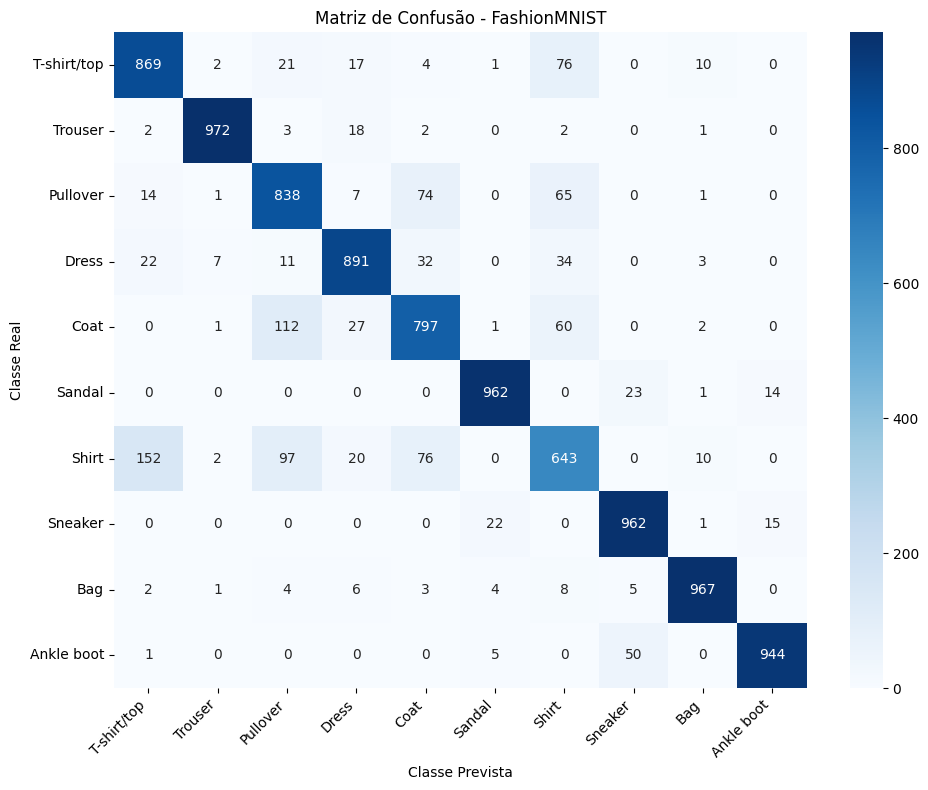

In [19]:

# 8. AVALIAÇÃO FINAL DO MODELO

model.eval()

y_true = []
y_pred = []
test_loss = 0
correct = 0
total = 0

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        outputs = model(inputs)
        loss = criterion(outputs, targets)

        predictions = outputs.argmax(dim=1)

        test_loss += loss.item() * inputs.size(0)
        correct += (predictions == targets).sum().item()
        total += targets.size(0)

        y_true.extend(targets.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

test_loss = test_loss / total
test_accuracy = correct / total
test_f1 = f1_score(y_true, y_pred, average='macro')

print('RESULTADOS FINAIS')
print(f'Loss de teste: {test_loss:.4f}')
print(f'Acurácia de teste: {test_accuracy:.2%}')
print(f'F1-Score: {test_f1:.4f}')

# MATRIZ DE CONFUSÃO
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=fashion_train.classes,
    yticklabels=fashion_train.classes
)

plt.title('Matriz de Confusão - FashionMNIST')
plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Análise da Avaliação Final

Na avaliação das 10.000 imagens de teste, o modelo obteve **Loss de 0,3159**, **acurácia de 88,45%** e **F1-score macro de 0,8839**. Foram classificadas corretamente **8.845 imagens**.

A matriz de confusão mostrou melhores resultados para **calça (972/1.000)**, **bolsa (967/1.000)**, **sandália (962/1.000)** e **tênis (962/1.000)**. A categoria **camisa** foi a mais difícil, com **643/1.000** acertos.

Entre os erros, destacam-se **152 camisas previstas como camisetas** e **112 casacos previstos como pulôveres**, indicando confusão entre peças visualmente semelhantes.

A acurácia no conjunto de teste (**88,45%**) ficou próxima da acurácia da melhor época de validação (**89,67%**), com diferença de **1,22 ponto percentual**. Esse resultado é compatível com uma boa capacidade de generalização, sem evidência de queda acentuada no conjunto de teste.

### Conclusões e Decisões de Projeto

O projeto teve como objetivo desenvolver uma rede neural artificial utilizando PyTorch para classificar imagens do dataset FashionMNIST.

A arquitetura MLP apresentou resultados satisfatórios, alcançando uma acurácia de 88,45% no conjunto de teste e F1-score de 0.8839.

Durante o desenvolvimento, um dos principais desafios foi organizar corretamente os tensores de entrada e saída, além de implementar manualmente as etapas de treinamento e validação.

As técnicas de Dropout, Weight Decay e Early Stopping foram utilizadas para controlar o treinamento e reduzir o risco de overfitting. O Early Stopping interrompeu o processo na 24ª época, recuperando os melhores pesos registrados na 19ª época.

A análise da matriz de confusão mostrou que o modelo apresentou maior dificuldade para diferenciar categorias visualmente semelhantes, especialmente camisas, camisetas, casacos e pulôveres.

Como possibilidade de melhoria, seria interessante testar uma Rede Neural Convolucional (CNN), que pode explorar melhor as características espaciais das imagens.

De modo geral, o projeto atingiu seu objetivo, demonstrando a aplicação prática dos conceitos de redes neurais, treinamento, regularização e avaliação de modelos utilizando PyTorch.